In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.config as conf
import UpROOT.physics.delphes as ph
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl
import UpROOT.fitting.delphes as fi
import UpROOT.delphes_root as dr

In [3]:
ANALYSIS = 'sm02_70GeV'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']
MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}

In [4]:
# cut = '(Eta < 5.0) & (Eta > 2)'
MUON_BRANCHES = (
    'event_id',
    'object_index',
    'PT',
    'Eta',
    'Phi',
    'Charge',
    'D0',
    'DZ',
    'ErrorD0',
    'ErrorDZ',
    'IsolationVar',
    'Particle_ref'
)

In [5]:
df_events = io.load_dataframe(
    branches=None,
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: mpmm02_70GeV_pandas.root
Árbol seleccionado: Events
Total de eventos: 200,000 eventos


,source_file_id,event_id,source_entry,root_uid,event_number,ReadTime,ProcTime,ProcessID,MPI,event_weight,...,PDF2,n_EFlowTrack,n_Electron,n_Jet,n_Muon,n_Particle,n_Photon,n_ScalarHT,n_Track,n_Weight
0,0,0,0,0,0,0.083756,0.003258,9999,-1,39874.886719,...,inf,25,0,0,0,991,0,1,25,292
1,0,1,1,0,1,0.000508,0.000537,9999,-1,35910.046875,...,inf,7,0,0,0,225,0,1,7,292
2,0,2,2,0,2,0.000228,0.000172,9999,-1,30808.257812,...,inf,2,0,0,0,86,0,1,2,292
3,0,3,3,0,3,0.000713,0.000561,9999,-1,38003.156250,...,inf,4,0,0,0,345,0,1,4,292
4,0,4,4,0,4,0.000235,0.000194,9999,-1,37238.570312,...,inf,1,0,0,0,91,0,1,1,292


In [6]:
df_muons = io.load_dataframe(
    branches=MUON_BRANCHES,
    dataset=PDATASET,
    tree_path='Muons'
)
df_muons.head(7)

Archivo: mpmm02_70GeV_pandas.root
Árbol seleccionado: Muons
Total de eventos: 16,537 eventos


,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref
0,22,0,11.335135,2.035917,2.751768,-1,0.011565,0.0,0.004124,0.0,0.0,627
1,56,0,1.029569,2.378531,2.192628,-1,-0.036500,0.0,0.021489,0.0,0.0,233
2,57,0,3.309614,2.336257,0.713197,-1,0.005141,0.0,-0.013486,0.0,0.0,84
3,67,0,2.153578,2.089530,-0.539304,1,0.011626,0.0,-0.004940,0.0,0.0,18
4,92,0,3.214316,2.418917,0.162490,1,0.011137,0.0,0.015474,0.0,0.0,13
5,99,0,2.685174,2.028148,-1.182010,-1,-0.028983,0.0,-0.023479,0.0,0.0,21
6,102,0,1.364428,2.353631,-2.059426,1,0.010950,0.0,-0.042474,0.0,0.0,15


In [7]:
cdf_muons = df_muons.loc[
    df_muons['PT'].ge(MIN_MUON_PT) & 
    df_muons['Eta'].between(*ETA_RANGE)
].copy()
print(f'Muones totales:       {len(df_muons):,}')
print(f'Muones seleccionados: {len(cdf_muons):,}')

Muones totales:       16,537
Muones seleccionados: 16,537


In [8]:
df_muons = ph.calc_four_momentum(df_muons)
df_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,22,0,11.335135,2.035917,2.751768,-1,0.011565,0.0,0.004124,0.0,0.0,627,-10.484726,4.307645,42.669493,44.149415,44.149542
1,56,0,1.029569,2.378531,2.192628,-1,-0.036500,0.0,0.021489,0.0,0.0,233,-0.599750,0.836847,5.506319,5.601746,5.602742
2,57,0,3.309614,2.336257,0.713197,-1,0.005141,0.0,-0.013486,0.0,0.0,84,2.502976,2.165331,16.954770,17.274772,17.275096
3,67,0,2.153578,2.089530,-0.539304,1,0.011626,0.0,-0.004940,0.0,0.0,18,1.847913,-1.105946,8.568410,8.834905,8.835536
4,92,0,3.214316,2.418917,0.162490,1,0.011137,0.0,0.015474,0.0,0.0,13,3.171975,0.519999,17.911245,18.197377,18.197683


In [9]:
cdf_muons = ph.calc_four_momentum(cdf_muons)
cdf_muons.head()

,event_id,object_index,PT,Eta,Phi,Charge,D0,DZ,ErrorD0,ErrorDZ,IsolationVar,Particle_ref,PX,PY,PZ,P,E
0,22,0,11.335135,2.035917,2.751768,-1,0.011565,0.0,0.004124,0.0,0.0,627,-10.484726,4.307645,42.669493,44.149415,44.149542
1,56,0,1.029569,2.378531,2.192628,-1,-0.036500,0.0,0.021489,0.0,0.0,233,-0.599750,0.836847,5.506319,5.601746,5.602742
2,57,0,3.309614,2.336257,0.713197,-1,0.005141,0.0,-0.013486,0.0,0.0,84,2.502976,2.165331,16.954770,17.274772,17.275096
3,67,0,2.153578,2.089530,-0.539304,1,0.011626,0.0,-0.004940,0.0,0.0,18,1.847913,-1.105946,8.568410,8.834905,8.835536
4,92,0,3.214316,2.418917,0.162490,1,0.011137,0.0,0.015474,0.0,0.0,13,3.171975,0.519999,17.911245,18.197377,18.197683


In [10]:
df_dimuons = ph.prepare_dimuon_analysis(
    df_muons, 
    events=df_events,
    min_muon_pt=MIN_MUON_PT,
    classify_displacement=True,
    prompt_max_significance=3.0,
    displaced_min_significance=5.0
)
df_dimuons.head()

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_dz,muplus_error_d0,muplus_error_dz,...,dimuon_rapidity,cos_theta_star,muplus_d0_significance,muminus_d0_significance,muplus_chi2_ip_proxy,muminus_chi2_ip_proxy,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,274,1,1.491621,2.073944,2.082376,1,-0.014183,0.0,0.008216,0.0,...,2.229661,0.111411,1.726333,NaN,2.980225,NaN,NaN,NaN,False,invalid
1,550,1,4.379896,2.247365,-1.859998,1,-0.008004,0.0,-0.029420,0.0,...,2.252726,0.004999,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
2,685,0,12.185843,2.149802,-0.786684,1,-0.001765,0.0,0.009090,0.0,...,2.174331,0.026685,0.194209,NaN,0.037717,NaN,NaN,NaN,False,invalid
3,822,0,2.262789,2.363922,1.253685,1,-0.004383,0.0,-0.000307,0.0,...,2.342462,-0.023322,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
4,847,0,1.435997,2.324666,2.056463,1,0.042774,0.0,-0.001607,0.0,...,2.290826,-0.033247,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid


In [11]:
display(df_dimuons[[
    "event_id", "dimuon_mass", "dimuon_pt", "delta_r",
    "sqrt_min_chi2_ip_proxy", "min_chi2_ip_proxy",
    "ip_proxy_valid", "displacement_category"
]].head())

,event_id,dimuon_mass,dimuon_pt,delta_r,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,274,3.223436,3.865001,1.548844,NaN,NaN,False,invalid
1,550,4.170744,9.009060,0.872597,NaN,NaN,False,invalid
2,685,22.429948,2.661838,2.967054,NaN,NaN,False,invalid
3,822,2.565081,3.032701,1.417938,NaN,NaN,False,invalid
4,847,2.609442,0.612549,2.704461,NaN,NaN,False,invalid


In [12]:
display(
    df_dimuons['displacement_category']
    .value_counts(dropna=False)
    .rename('candidatos')
)

displacement_category
invalid      671
prompt       147
mixed         67
displaced      2
Name: candidatos, dtype: int64

In [13]:
cdf_dimuons = ph.prepare_dimuon_analysis(
    cdf_muons, 
    events=df_events,
    min_muon_pt=MIN_MUON_PT,
    classify_displacement=True,
    prompt_max_significance=3.0,
    displaced_min_significance=5.0
)
cdf_dimuons.head(7)

,event_id,muplus_index,muplus_pt,muplus_eta,muplus_phi,muplus_charge,muplus_d0,muplus_dz,muplus_error_d0,muplus_error_dz,...,dimuon_rapidity,cos_theta_star,muplus_d0_significance,muminus_d0_significance,muplus_chi2_ip_proxy,muminus_chi2_ip_proxy,sqrt_min_chi2_ip_proxy,min_chi2_ip_proxy,ip_proxy_valid,displacement_category
0,274,1,1.491621,2.073944,2.082376,1,-0.014183,0.0,0.008216,0.0,...,2.229661,0.111411,1.726333,NaN,2.980225,NaN,NaN,NaN,False,invalid
1,550,1,4.379896,2.247365,-1.859998,1,-0.008004,0.0,-0.029420,0.0,...,2.252726,0.004999,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
2,685,0,12.185843,2.149802,-0.786684,1,-0.001765,0.0,0.009090,0.0,...,2.174331,0.026685,0.194209,NaN,0.037717,NaN,NaN,NaN,False,invalid
3,822,0,2.262789,2.363922,1.253685,1,-0.004383,0.0,-0.000307,0.0,...,2.342462,-0.023322,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
4,847,0,1.435997,2.324666,2.056463,1,0.042774,0.0,-0.001607,0.0,...,2.290826,-0.033247,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid
5,860,1,2.528010,2.020755,0.228346,1,0.009498,0.0,0.013435,0.0,...,2.219781,0.187045,0.706974,5.644253,0.499813,31.857588,0.706974,0.499813,True,mixed
6,1145,0,11.722084,2.218823,1.055938,1,0.017239,0.0,-0.010004,0.0,...,2.238330,0.021835,NaN,NaN,NaN,NaN,NaN,NaN,False,invalid


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\event_multiplicities_70GeV_01.png.


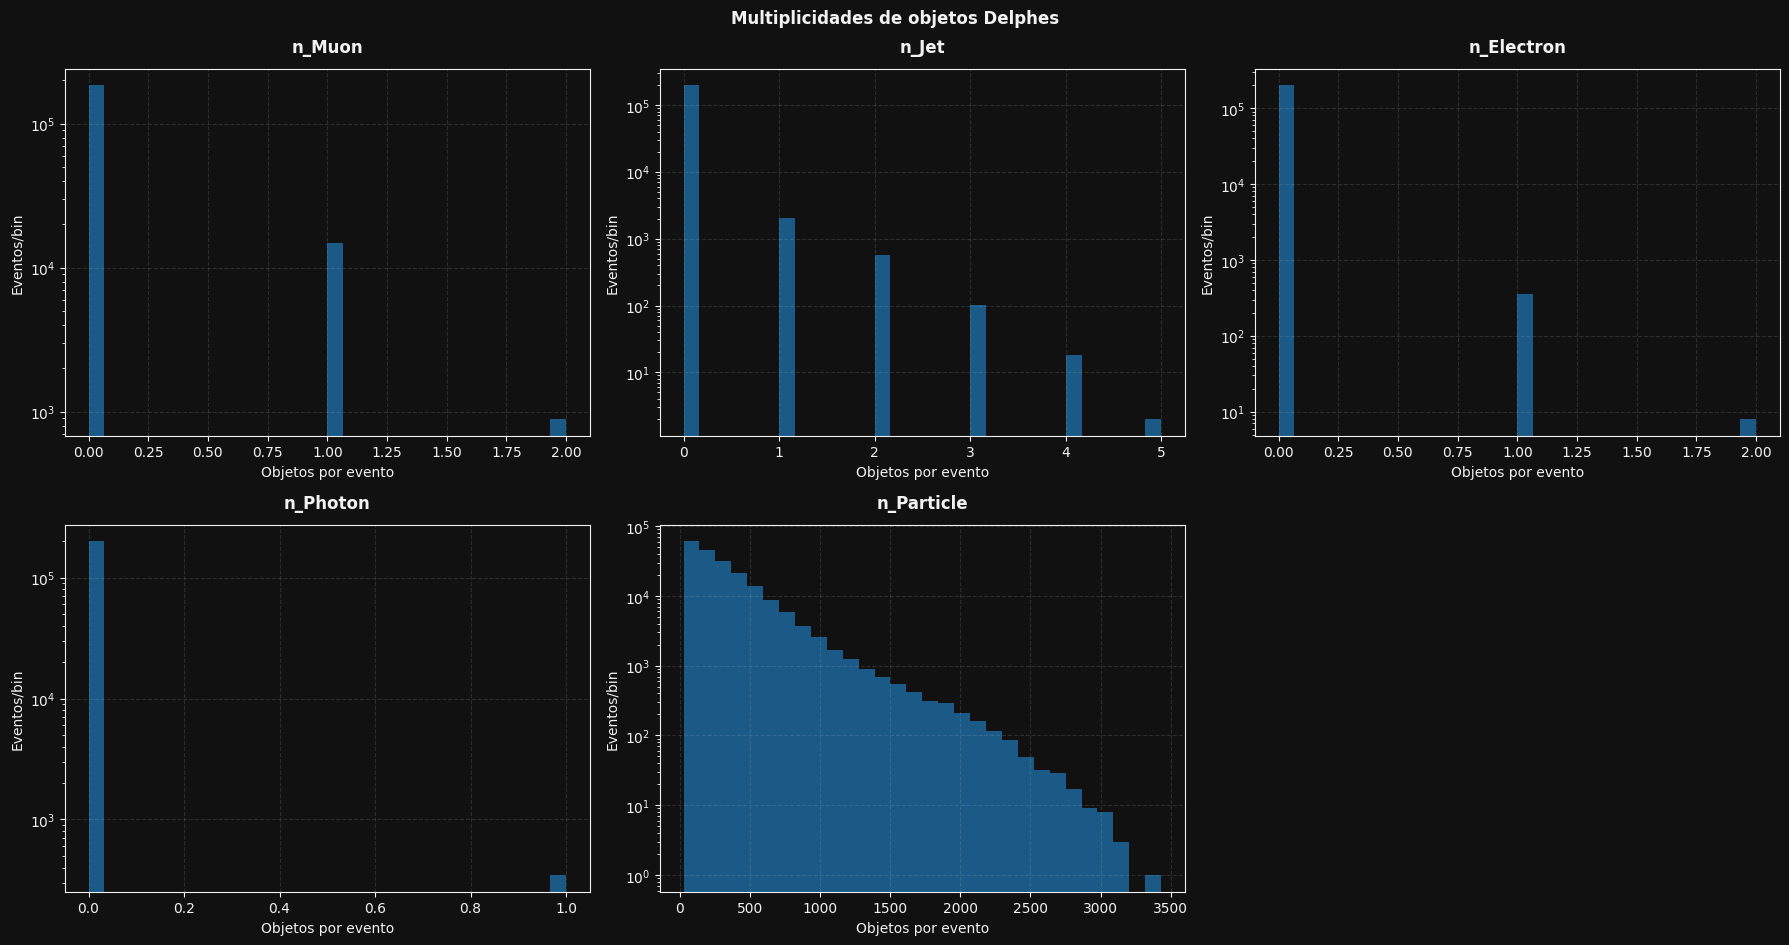

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Photon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >]], dtype=object))

In [14]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities_70GeV_01',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\muon_kinematics_70GeV_01.png.


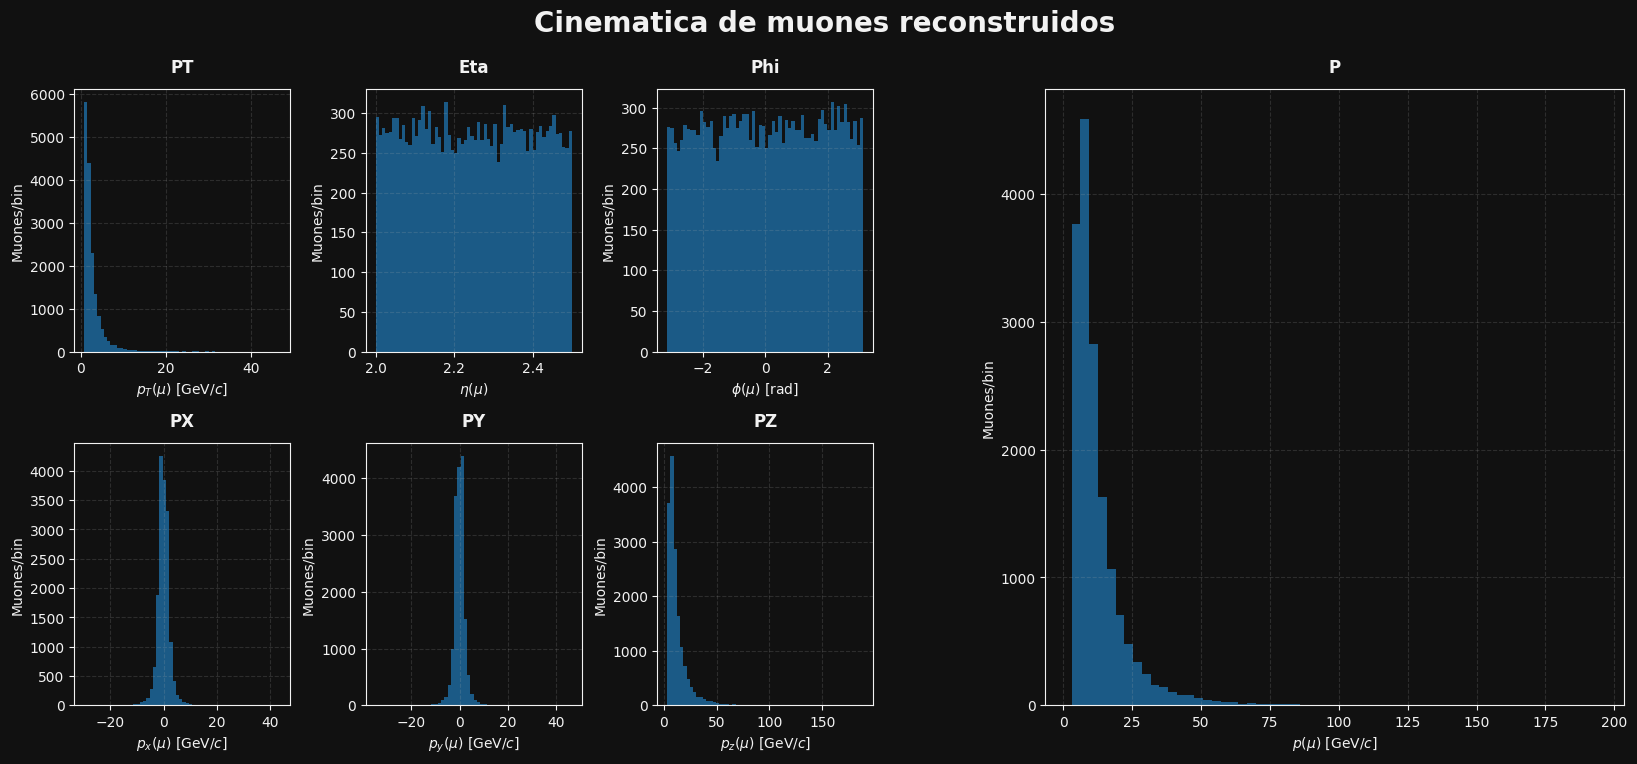

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [15]:
pt.plot_muon_kinematics(
    df_muons, 
    bins=60, 
    filename="muon_kinematics_70GeV_01",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\muon_kinematics_70GeV_01_cut.png.


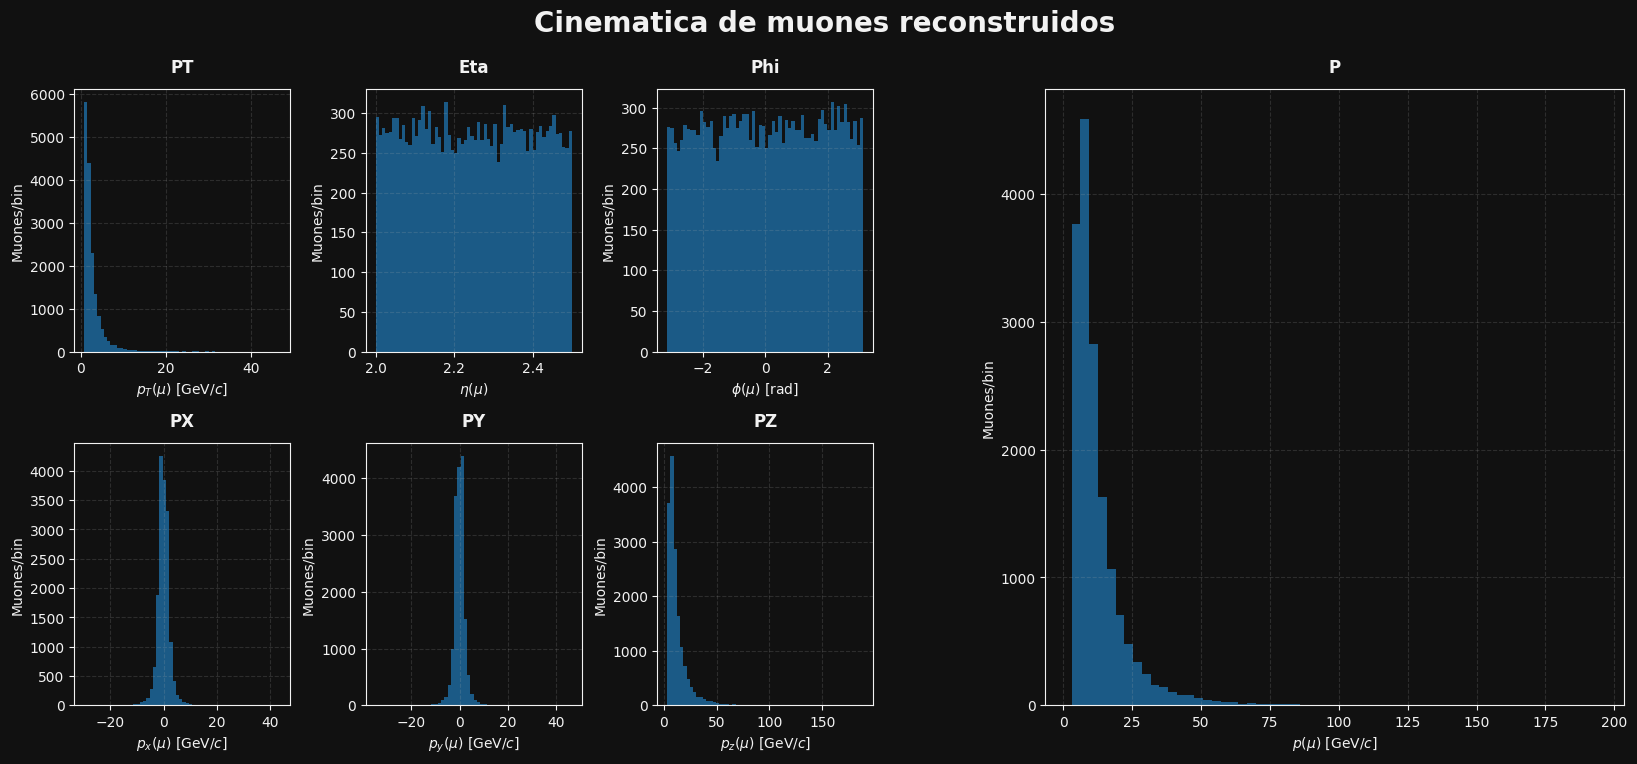

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [16]:
pt.plot_muon_kinematics(
    cdf_muons, 
    bins=60,
    filename="muon_kinematics_70GeV_01_cut",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\muon_kinematics_70GeV_02.png.


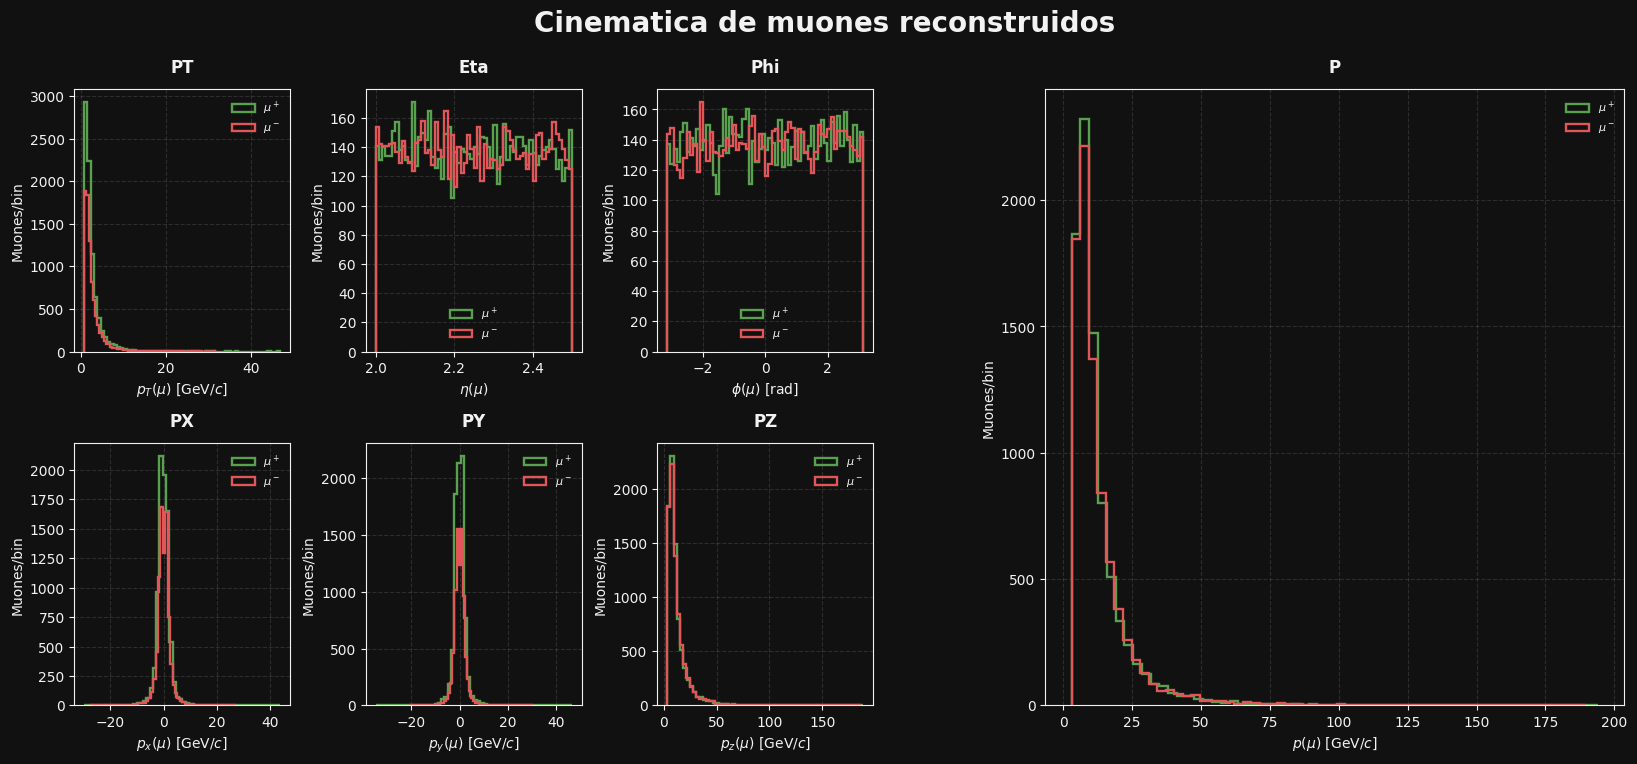

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [17]:
pt.plot_muon_kinematics(
    df_muons, 
    bins=60, 
    split_charge=True, 
    filename="muon_kinematics_70GeV_02",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\muon_kinematics_70GeV_02_cut.png.


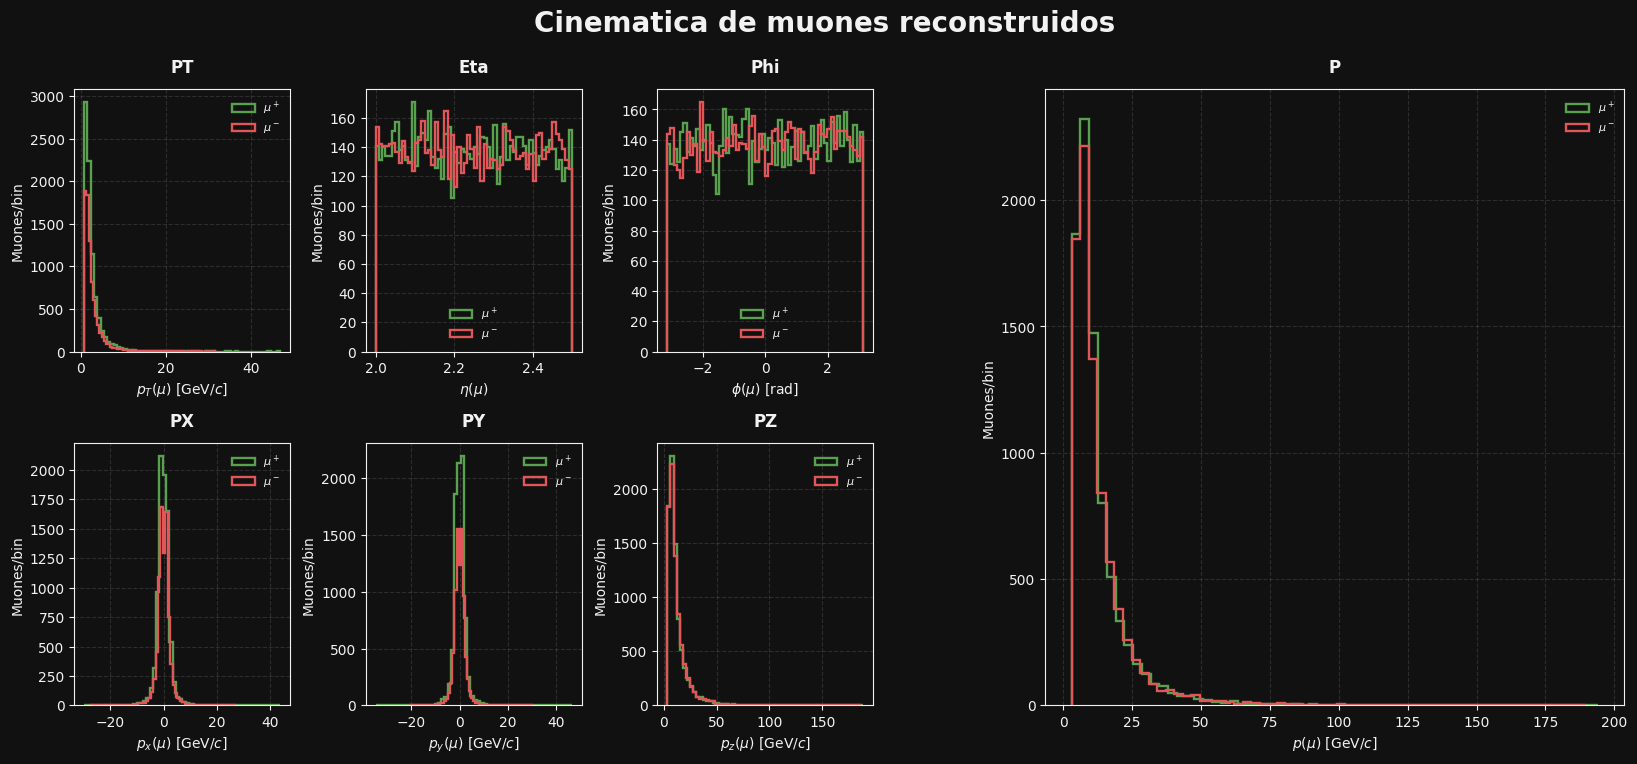

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [18]:
pt.plot_muon_kinematics(
    cdf_muons, 
    bins=60, 
    split_charge=True,
    filename="muon_kinematics_70GeV_02_cut",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\sm_model\c02\dimuon_mass_70GeV_01.png.


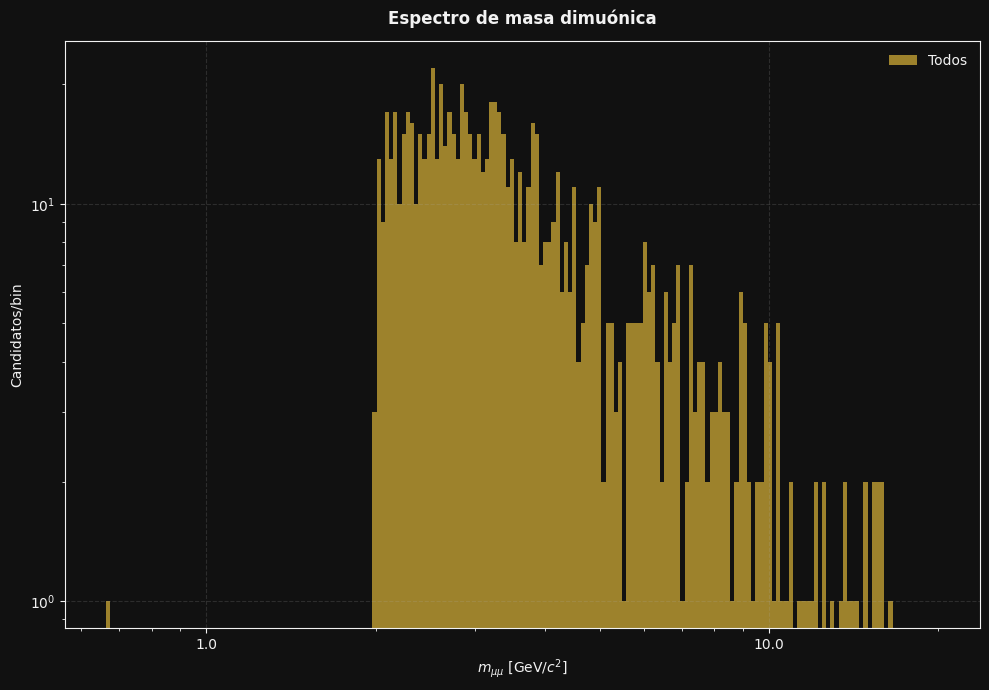

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Espectro de masa dimuónica'}, xlabel='$m_{\\mu\\mu}$ [GeV/$c^2$]', ylabel='Candidatos/bin'>)

In [21]:
pt.plot_dimuon_mass(
    df_dimuons,
    bins=200, 
    log_x=True,
    log_y=True,
    mass_range=(0.0, 20.0),
    filename="dimuon_mass_70GeV_01",
    **plot_options
)

In [20]:
pt.plot_dimuon_mass(
    cdf_dimuons, 
    bins=500, 
    log_x=True,
    log_y=True, 
    filename="dimuon_mass_70GeV_01_cut",
    **plot_options
)

AttributeError: module 'numpy' has no attribute 'float'.
`np.float` was a deprecated alias for the builtin `float`. To avoid this error in existing code, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations